<a href="https://colab.research.google.com/github/AaronGoldblatt/persistent-pepper/blob/main/notebooks/pepper_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pepper Inference

Colab-friendly notebook for loading a Textual Inversion or DreamBooth
checkpoint produced by this repo and sampling Pepper images from prompts
with the manual DDIM sampler defined in `src/utils/sampling.py`.

**Important**: this notebook only *uses* the building blocks in `src/`; it
does not introduce a pipeline wrapper. Every diffusion step is still run
through our hand-written sampler.

## 0. Colab bootstrap (skip locally)

In [1]:
from pathlib import Path
import subprocess

RUNNING_IN_COLAB = False
try:
    import google.colab  # noqa: F401
    RUNNING_IN_COLAB = True
except ImportError:
    pass

if RUNNING_IN_COLAB:
    from google.colab import drive

    DRIVE_MOUNT_ROOT = '/content/gdrive'
    drive.mount(DRIVE_MOUNT_ROOT)

    MY_DRIVE_ROOT = Path(DRIVE_MOUNT_ROOT) / 'MyDrive'
    DRIVE_PROJECT_ROOT = MY_DRIVE_ROOT / 'persistent-pepper'
    DRIVE_CREDENTIALS_DIRECTORY = MY_DRIVE_ROOT / 'cs5788'
    DRIVE_CACHE_ROOT = DRIVE_PROJECT_ROOT / 'cache'
    DRIVE_CHECKPOINTS_ROOT = DRIVE_CACHE_ROOT / 'checkpoints'
    DRIVE_PROCESSED_IMAGES_DIRECTORY = DRIVE_CACHE_ROOT / 'processed'
    DRIVE_SD_MODEL_DIRECTORY = DRIVE_CACHE_ROOT / 'sd-v1-5'

    GITHUB_TOKEN_FILE_PATH = DRIVE_CREDENTIALS_DIRECTORY / 'token.txt'
    GITHUB_USERNAME_FILE_PATH = DRIVE_CREDENTIALS_DIRECTORY / 'git_username.txt'
    GITHUB_REPOSITORY_OWNER = 'AaronGoldblatt'
    GITHUB_REPOSITORY_NAME = 'persistent-pepper'
    BRANCH_NAME = 'main'
    LOCAL_REPOSITORY_ROOT = Path('/content/persistent-pepper')

    if not GITHUB_TOKEN_FILE_PATH.is_file():
        raise FileNotFoundError(
            f'Missing GitHub token file: {GITHUB_TOKEN_FILE_PATH}. '
            'Create it in Drive with only the token on the first line.'
        )
    if not GITHUB_USERNAME_FILE_PATH.is_file():
        raise FileNotFoundError(
            f'Missing GitHub username file: {GITHUB_USERNAME_FILE_PATH}. '
            'Create it in Drive with only your GitHub username on the first line.'
        )

    github_token = GITHUB_TOKEN_FILE_PATH.read_text().strip().splitlines()[0]
    github_username = GITHUB_USERNAME_FILE_PATH.read_text().strip().splitlines()[0]
    authenticated_repository_url = (
        f'https://{github_token}@github.com/'
        f'{GITHUB_REPOSITORY_OWNER}/{GITHUB_REPOSITORY_NAME}.git'
    )
    public_repository_url = (
        f'https://github.com/{GITHUB_REPOSITORY_OWNER}/{GITHUB_REPOSITORY_NAME}.git'
    )

    def run_git_command(command_parts, working_directory=None):
        completed_process = subprocess.run(
            command_parts,
            cwd=working_directory,
            capture_output=True,
            text=True,
        )
        if completed_process.returncode != 0:
            sanitized_command_parts = [
                command_part.replace(github_token, '[GITHUB_TOKEN]')
                for command_part in command_parts
            ]
            sanitized_stderr = completed_process.stderr.replace(github_token, '[GITHUB_TOKEN]')
            sanitized_stdout = completed_process.stdout.replace(github_token, '[GITHUB_TOKEN]')
            raise RuntimeError(
                'Git command failed:\n'
                f'command: {sanitized_command_parts}\n'
                f'stdout: {sanitized_stdout}\n'
                f'stderr: {sanitized_stderr}'
            )
        return completed_process

    if not LOCAL_REPOSITORY_ROOT.exists():
        run_git_command(
            [
                'git',
                'clone',
                '--branch',
                BRANCH_NAME,
                '--single-branch',
                authenticated_repository_url,
                str(LOCAL_REPOSITORY_ROOT),
            ]
        )
    else:
        run_git_command(
            ['git', 'remote', 'set-url', 'origin', authenticated_repository_url],
            working_directory=LOCAL_REPOSITORY_ROOT,
        )
        run_git_command(
            ['git', 'checkout', BRANCH_NAME],
            working_directory=LOCAL_REPOSITORY_ROOT,
        )
        run_git_command(
            ['git', 'pull', '--ff-only'],
            working_directory=LOCAL_REPOSITORY_ROOT,
        )

    run_git_command(
        ['git', 'remote', 'set-url', 'origin', public_repository_url],
        working_directory=LOCAL_REPOSITORY_ROOT,
    )

    %cd {LOCAL_REPOSITORY_ROOT}
    !python -m pip -q install -r requirements.txt

    REPOSITORY_ROOT = str(LOCAL_REPOSITORY_ROOT)
    print(f'Using private repo {GITHUB_REPOSITORY_OWNER}/{GITHUB_REPOSITORY_NAME} as {github_username}.')
else:
    REPOSITORY_ROOT = str(Path().resolve().parent)
    DRIVE_CHECKPOINTS_ROOT = Path(REPOSITORY_ROOT) / 'checkpoints'
    DRIVE_PROCESSED_IMAGES_DIRECTORY = Path(REPOSITORY_ROOT) / 'data' / 'processed'
    DRIVE_SD_MODEL_DIRECTORY = Path(REPOSITORY_ROOT) / 'checkpoints' / 'sd-v1-5'

print('Repository root:', REPOSITORY_ROOT)
print('Checkpoints root:', DRIVE_CHECKPOINTS_ROOT)

Mounted at /content/gdrive
/content/persistent-pepper
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 136.0 MB/s eta 0:00:00
Using private repo AaronGoldblatt/persistent-pepper as AaronGoldblatt.
Repository root: /content/persistent-pepper
Checkpoints root: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints


## 1. Put the repo on `sys.path` and import building blocks

In [2]:
import sys
sys.path.insert(0, REPOSITORY_ROOT)

import torch
from pathlib import Path
import matplotlib.pyplot as plt

from src.models import load_stable_diffusion_components
from src.utils.sampling import SamplingConfiguration, sample_images_from_prompts

pretrained_model_name_or_path = str(DRIVE_SD_MODEL_DIRECTORY)
if not Path(pretrained_model_name_or_path).exists():
    pretrained_model_name_or_path = 'stable-diffusion-v1-5/stable-diffusion-v1-5'

stable_diffusion_components = load_stable_diffusion_components(
    pretrained_model_name_or_path=pretrained_model_name_or_path,
    working_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
)
print('Loaded SD 1.5 onto', stable_diffusion_components.working_device)
print('Using model source:', pretrained_model_name_or_path)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded SD 1.5 onto cuda
Using model source: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5


## 2a. Load a Textual Inversion checkpoint (skip if using DreamBooth)

In [5]:
from scripts.evaluate import load_textual_inversion_embedding_into_components

learned_embedding_checkpoint_path = (
    DRIVE_CHECKPOINTS_ROOT / 'textual_inversion' / 'learned_embedding_final.bin'
)

placeholder_token_string = load_textual_inversion_embedding_into_components(
    stable_diffusion_components=stable_diffusion_components,
    learned_embedding_checkpoint_path=learned_embedding_checkpoint_path,
)
print('Loaded textual inversion embedding:', placeholder_token_string)
print('Checkpoint path:', learned_embedding_checkpoint_path)

subject_phrase_for_prompts = placeholder_token_string

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Loaded textual inversion embedding: <pepper>
Checkpoint path: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/textual_inversion/learned_embedding_final.bin


## 2b. Load a DreamBooth checkpoint (skip if using Textual Inversion)

In [3]:
from scripts.evaluate import load_dreambooth_weights_into_components

dreambooth_checkpoint_directory = DRIVE_CHECKPOINTS_ROOT / 'dreambooth' / 'latest'

load_dreambooth_weights_into_components(
    stable_diffusion_components=stable_diffusion_components,
    dreambooth_checkpoint_directory=dreambooth_checkpoint_directory,
)
print('Loaded DreamBooth checkpoint:', dreambooth_checkpoint_directory)

subject_phrase_for_prompts = 'sks dog'

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded DreamBooth checkpoint: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/dreambooth/latest


## 3. Sample images

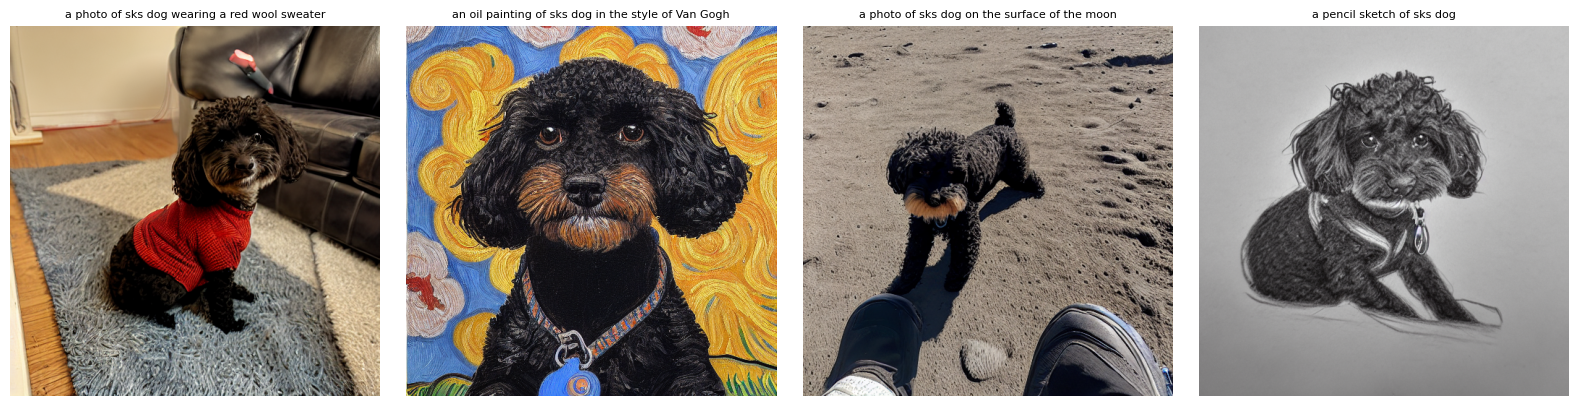

In [4]:
prompt_templates = [
    'a photo of {subject} wearing a red wool sweater',
    'an oil painting of {subject} in the style of Van Gogh',
    'a photo of {subject} on the surface of the moon',
    'a pencil sketch of {subject}',
]
fully_substituted_prompts = [
    prompt_template.format(subject=subject_phrase_for_prompts)
    for prompt_template in prompt_templates
]

sampling_configuration = SamplingConfiguration(
    number_of_inference_steps=50,
    classifier_free_guidance_scale=7.5,
    random_seed=42,
)

generated_pil_images = sample_images_from_prompts(
    stable_diffusion_components=stable_diffusion_components,
    prompt_texts=fully_substituted_prompts,
    sampling_configuration=sampling_configuration,
)

figure, axes_grid = plt.subplots(
    1,
    len(generated_pil_images),
    figsize=(4 * len(generated_pil_images), 4),
)
if len(generated_pil_images) == 1:
    axes_grid = [axes_grid]
for axis, generated_pil_image, fully_substituted_prompt in zip(
    axes_grid,
    generated_pil_images,
    fully_substituted_prompts,
):
    axis.imshow(generated_pil_image)
    axis.set_title(fully_substituted_prompt, fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()

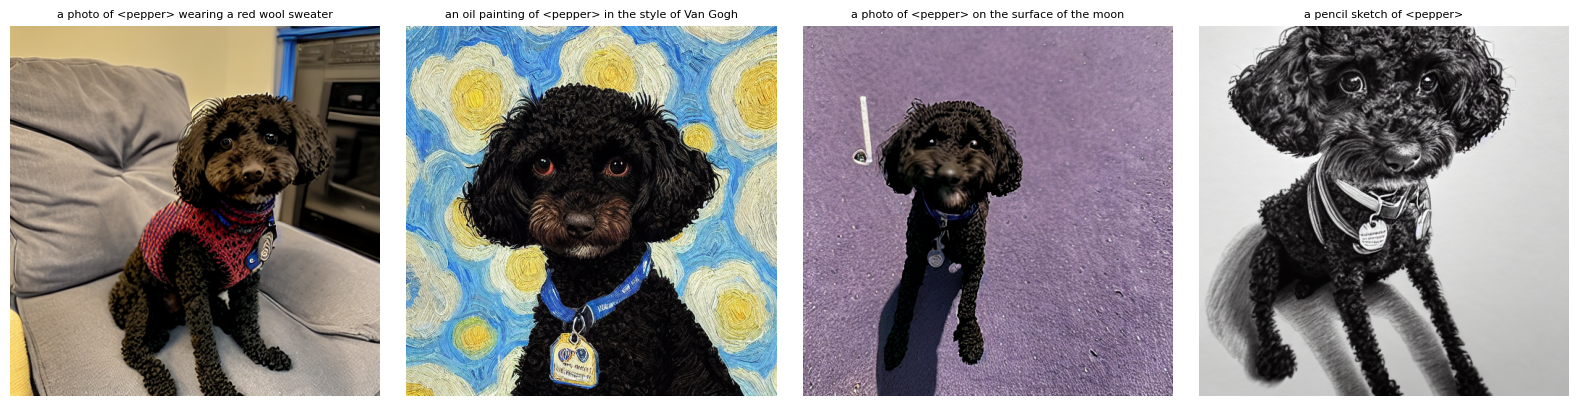

In [6]:
prompt_templates = [
    'a photo of {subject} wearing a red wool sweater',
    'an oil painting of {subject} in the style of Van Gogh',
    'a photo of {subject} on the surface of the moon',
    'a pencil sketch of {subject}',
]
fully_substituted_prompts = [
    prompt_template.format(subject=subject_phrase_for_prompts)
    for prompt_template in prompt_templates
]

sampling_configuration = SamplingConfiguration(
    number_of_inference_steps=50,
    classifier_free_guidance_scale=7.5,
    random_seed=42,
)

generated_pil_images = sample_images_from_prompts(
    stable_diffusion_components=stable_diffusion_components,
    prompt_texts=fully_substituted_prompts,
    sampling_configuration=sampling_configuration,
)

figure, axes_grid = plt.subplots(
    1,
    len(generated_pil_images),
    figsize=(4 * len(generated_pil_images), 4),
)
if len(generated_pil_images) == 1:
    axes_grid = [axes_grid]
for axis, generated_pil_image, fully_substituted_prompt in zip(
    axes_grid,
    generated_pil_images,
    fully_substituted_prompts,
):
    axis.imshow(generated_pil_image)
    axis.set_title(fully_substituted_prompt, fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 4. Optional: CLIP-based identity / prompt alignment report

In [7]:
from src.utils.metrics import (
    compute_clip_similarity_report,
    format_report_as_human_readable_text,
    load_pil_images_from_directory,
)

reference_pil_images = load_pil_images_from_directory(
    DRIVE_PROCESSED_IMAGES_DIRECTORY
)
clip_similarity_report = compute_clip_similarity_report(
    generated_pil_images=generated_pil_images,
    reference_pil_images=reference_pil_images,
    prompts_used_for_generation=fully_substituted_prompts,
)
print(format_report_as_human_readable_text(clip_similarity_report))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

RuntimeError: mat1 and mat2 shapes cannot be multiplied (4x768 and 1024x768)

## 5. Custom prompt: one method or both

Use this section when you want to type one prompt and render it with Textual Inversion, DreamBooth, or both methods side-by-side. The prompt should contain `{subject}`, which will be replaced with either `<pepper>` or `sks dog` depending on the method.

This cell reloads a fresh SD 1.5 component bundle per method so the two methods do not accidentally overwrite each other's weights.

Generating with Textual Inversion (<pepper>)...


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generating with DreamBooth (sks dog)...


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

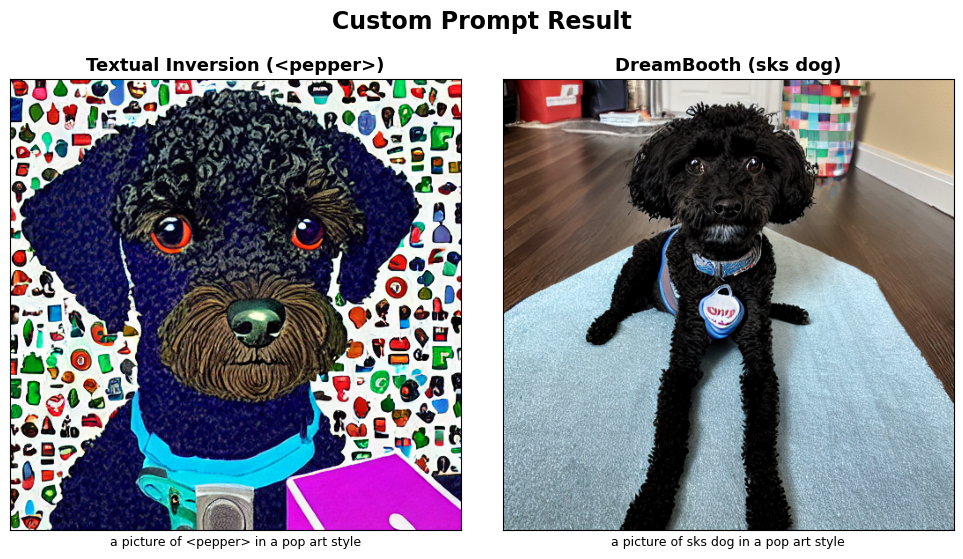

Saved textual_inversion image to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/custom_prompt_outputs/textual_inversion_a_picture_of_pepper_in_a_pop_art_style.png
Saved dreambooth image to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/custom_prompt_outputs/dreambooth_a_picture_of_pepper_in_a_pop_art_style.png


In [10]:
import gc
import textwrap

from scripts.evaluate import (
    load_dreambooth_weights_into_components,
    load_textual_inversion_embedding_into_components,
)

# Edit these two values for interactive use.
CUSTOM_PROMPT_TEMPLATE = 'a picture of {subject} in a pop art style'
METHODS_TO_RENDER = ['textual_inversion', 'dreambooth']  # choose: ['textual_inversion'], ['dreambooth'], or both

CUSTOM_SAMPLING_CONFIGURATION = SamplingConfiguration(
    number_of_inference_steps=50,
    classifier_free_guidance_scale=7.5,
    random_seed=123,
)

CUSTOM_METHOD_SETTINGS = {
    'textual_inversion': {
        'display_name': 'Textual Inversion (<pepper>)',
        'subject_identifier_phrase': '<pepper>',
        'checkpoint_path': DRIVE_CHECKPOINTS_ROOT / 'textual_inversion' / 'learned_embedding_final.bin',
    },
    'dreambooth': {
        'display_name': 'DreamBooth (sks dog)',
        'subject_identifier_phrase': 'sks dog',
        'checkpoint_path': DRIVE_CHECKPOINTS_ROOT / 'dreambooth' / 'latest',
    },
}

custom_generated_images_by_method = {}
custom_prompt_by_method = {}

for method_name in METHODS_TO_RENDER:
    if method_name not in CUSTOM_METHOD_SETTINGS:
        raise ValueError(
            f'Unknown method {method_name!r}. Expected one of: {list(CUSTOM_METHOD_SETTINGS)}'
        )

    method_settings = CUSTOM_METHOD_SETTINGS[method_name]
    custom_prompt_text = CUSTOM_PROMPT_TEMPLATE.format(
        subject=method_settings['subject_identifier_phrase']
    )
    custom_prompt_by_method[method_name] = custom_prompt_text

    print(f"Generating with {method_settings['display_name']}...")
    method_components = load_stable_diffusion_components(
        pretrained_model_name_or_path=pretrained_model_name_or_path,
        working_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    )

    if method_name == 'textual_inversion':
        load_textual_inversion_embedding_into_components(
            stable_diffusion_components=method_components,
            learned_embedding_checkpoint_path=method_settings['checkpoint_path'],
        )
    elif method_name == 'dreambooth':
        load_dreambooth_weights_into_components(
            stable_diffusion_components=method_components,
            dreambooth_checkpoint_directory=method_settings['checkpoint_path'],
        )

    generated_image = sample_images_from_prompts(
        stable_diffusion_components=method_components,
        prompt_texts=[custom_prompt_text],
        sampling_configuration=CUSTOM_SAMPLING_CONFIGURATION,
    )[0]
    custom_generated_images_by_method[method_name] = generated_image

    del method_components
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

figure, axes_grid = plt.subplots(
    1,
    len(METHODS_TO_RENDER),
    figsize=(5.0 * len(METHODS_TO_RENDER), 5.2),
    squeeze=False,
)

for axis, method_name in zip(axes_grid[0], METHODS_TO_RENDER):
    method_settings = CUSTOM_METHOD_SETTINGS[method_name]
    axis.imshow(custom_generated_images_by_method[method_name])
    axis.set_title(
        method_settings['display_name'],
        fontsize=13,
        weight='bold',
    )
    axis.set_xlabel(
        textwrap.fill(custom_prompt_by_method[method_name], width=45),
        fontsize=9,
    )
    axis.set_xticks([])
    axis.set_yticks([])

figure.suptitle(
    'Custom Prompt Result',
    fontsize=17,
    weight='bold',
    y=1.03,
)
figure.tight_layout()
plt.show()

custom_output_directory = DRIVE_CHECKPOINTS_ROOT / 'custom_prompt_outputs'
custom_output_directory.mkdir(parents=True, exist_ok=True)

for method_name, generated_image in custom_generated_images_by_method.items():
    safe_prompt_stub = ''.join(
        character if character.isalnum() else '_'
        for character in CUSTOM_PROMPT_TEMPLATE.format(subject='pepper').lower()
    )[:80]
    output_image_path = custom_output_directory / f'{method_name}_{safe_prompt_stub}.png'
    generated_image.save(output_image_path)
    print(f'Saved {method_name} image to:', output_image_path)

## 6. Human Evaluation — Generate Image Sets

Generates **12 prompts × 2 seeds = 24 images per method** (48 total) for the human
evaluation study. Each image is saved to Drive under
`checkpoints/human_eval/{method}/` with a filename like `TI_p01_seed000.png` that
directly cross-references the `image_id` column in the rating CSVs at
`data/human_eval_ratings/`.

**Rating scale used by all raters (1–5):**
- **Identity Fidelity** — *How closely does the dog look like Pepper?*  
  (1 = clearly a different dog, 5 = unmistakably Pepper)
- **Prompt Alignment** — *How well does the image match the described scenario?*  
  (1 = completely ignores the prompt, 5 = perfectly matches it)
- **Overall Quality** — *How natural and realistic does the image look?*  
  (1 = obvious artifacts / distorted, 5 = photorealistic)

After running the cells below: commit the updated CSVs from `data/human_eval_ratings/`
and import each file as a separate tab in a shared Google Sheet for raters to fill in.

In [ ]:
import csv
import gc
import math

import matplotlib.pyplot as plt
import torch
from PIL import Image

from scripts.evaluate import (
    load_dreambooth_weights_into_components,
    load_textual_inversion_embedding_into_components,
)

# ── Study configuration ───────────────────────────────────────────────────────
HUMAN_EVAL_PROMPTS = [
    'a photo of {subject} sitting on a couch',
    'a close-up portrait of {subject}',
    'a photo of {subject} wearing sunglasses',
    'an oil painting of {subject} in the style of Van Gogh',
    'a photo of {subject} sitting on a wooden park bench',
    'a photo of {subject} wearing a red wool sweater',
    'a photo of {subject} on the surface of the moon',
    'a pencil sketch of {subject}',
    'a photo of {subject} swimming in a pool',
    'a photo of {subject} as a character in a Studio Ghibli film',
    'a cyberpunk illustration of {subject} with neon lights',
    'a watercolor painting of {subject} in a field of flowers',
]
HUMAN_EVAL_SEEDS = [0, 42]  # 12 prompts x 2 seeds = 24 images per method
HUMAN_EVAL_ROOT  = DRIVE_CHECKPOINTS_ROOT / 'human_eval'

HUMAN_EVAL_CONFIG = {
    'textual_inversion': {
        'short_id':        'TI',
        'subject_phrase':  '<pepper>',
        'checkpoint_path': DRIVE_CHECKPOINTS_ROOT / 'textual_inversion' / 'learned_embedding_final.bin',
    },
    'dreambooth': {
        'short_id':        'DB',
        'subject_phrase':  'sks dog',
        'checkpoint_path': DRIVE_CHECKPOINTS_ROOT / 'dreambooth' / 'latest',
    },
}

# ── Generate images (loads each model once) ───────────────────────────────────
for method_name, cfg in HUMAN_EVAL_CONFIG.items():
    out_dir = HUMAN_EVAL_ROOT / method_name
    out_dir.mkdir(parents=True, exist_ok=True)
    short = cfg['short_id']

    print(f'\n=== {method_name}: loading model ===')
    sd = load_stable_diffusion_components(
        pretrained_model_name_or_path=pretrained_model_name_or_path,
        working_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    )
    if method_name == 'textual_inversion':
        load_textual_inversion_embedding_into_components(
            stable_diffusion_components=sd,
            learned_embedding_checkpoint_path=cfg['checkpoint_path'],
        )
    else:
        load_dreambooth_weights_into_components(
            stable_diffusion_components=sd,
            dreambooth_checkpoint_directory=cfg['checkpoint_path'],
        )

    subject = cfg['subject_phrase']
    prompts = [p.format(subject=subject) for p in HUMAN_EVAL_PROMPTS]

    for seed in HUMAN_EVAL_SEEDS:
        print(f'  Generating seed {seed}...')
        images = sample_images_from_prompts(
            stable_diffusion_components=sd,
            prompt_texts=prompts,
            sampling_configuration=SamplingConfiguration(
                number_of_inference_steps=50,
                classifier_free_guidance_scale=7.5,
                random_seed=seed,
            ),
        )
        for p_idx, img in enumerate(images):
            fname = f'{short}_p{p_idx + 1:02d}_seed{seed:03d}.png'
            img.save(out_dir / fname)
        print(f'    Saved {len(images)} images  ->  {out_dir}')

    del sd
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f'  Done with {method_name}.')

print('\nAll 48 human-eval images saved to', HUMAN_EVAL_ROOT)


In [ ]:
# ── Contact sheets: one labeled grid per method for raters to reference ──────
for method_name, cfg in HUMAN_EVAL_CONFIG.items():
    out_dir   = HUMAN_EVAL_ROOT / method_name
    short     = cfg['short_id']
    img_paths = sorted(out_dir.glob('*.png'))
    n         = len(img_paths)
    n_cols    = 4
    n_rows    = math.ceil(n / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols,
                              figsize=(4.2 * n_cols, 4.8 * n_rows),
                              squeeze=False)

    for idx, path in enumerate(img_paths):
        row, col   = divmod(idx, n_cols)
        ax         = axes[row][col]
        ax.imshow(Image.open(path).convert('RGB'))
        ax.axis('off')
        stem_parts = path.stem.split('_')          # e.g. ['TI', 'p03', 'seed042']
        p_idx      = int(stem_parts[1][1:]) - 1    # 0-based
        seed_val   = int(stem_parts[2].replace('seed', ''))
        prompt_short = HUMAN_EVAL_PROMPTS[p_idx].replace('{subject}', 'Pepper')
        img_id     = f'{short}_p{p_idx + 1:02d}_seed{seed_val:03d}'
        ax.set_title(
            f'[{img_id}]\n{prompt_short[:42]}',
            fontsize=7.5, pad=4,
        )

    for idx in range(n, n_rows * n_cols):
        row, col = divmod(idx, n_cols)
        axes[row][col].axis('off')

    method_label = method_name.replace('_', ' ').title()
    fig.suptitle(
        f'{method_label} — Human Evaluation Contact Sheet\n'
        'Rate 1-5: Identity Fidelity  |  Prompt Alignment  |  Overall Quality',
        fontsize=11, weight='bold',
    )
    fig.tight_layout()
    sheet_path = HUMAN_EVAL_ROOT / f'contact_sheet_{method_name}.png'
    fig.savefig(sheet_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Contact sheet saved: {sheet_path}')

# ── Re-write rating CSV templates into the local repo ────────────────────────
# The same files already exist in data/human_eval_ratings/; this regenerates
# them in case prompts or seeds changed.
RATING_HEADERS = [
    'image_id', 'prompt_number', 'prompt_text', 'seed',
    'aaron_identity_fidelity', 'aaron_prompt_alignment', 'aaron_overall_quality',
    'leah_identity_fidelity',  'leah_prompt_alignment',  'leah_overall_quality',
    'judah_identity_fidelity', 'judah_prompt_alignment', 'judah_overall_quality',
    'notes',
]

csv_repo_dir = Path(REPOSITORY_ROOT) / 'data' / 'human_eval_ratings'
csv_repo_dir.mkdir(parents=True, exist_ok=True)

for method_name, cfg in HUMAN_EVAL_CONFIG.items():
    short = cfg['short_id']
    rows  = []
    for p_idx, prompt_template in enumerate(HUMAN_EVAL_PROMPTS, start=1):
        for seed in HUMAN_EVAL_SEEDS:
            image_id = f'{short}_p{p_idx:02d}_seed{seed:03d}'
            rows.append({
                'image_id':      image_id,
                'prompt_number': p_idx,
                'prompt_text':   prompt_template.replace('{subject}', 'Pepper'),
                'seed':          seed,
                **{h: '' for h in RATING_HEADERS
                   if h not in ('image_id', 'prompt_number', 'prompt_text', 'seed')},
            })

    csv_path = csv_repo_dir / f'ratings_{method_name}.csv'
    with open(csv_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=RATING_HEADERS)
        writer.writeheader()
        writer.writerows(rows)
    print(f'Rating template written: {csv_path}  ({len(rows)} rows)')

print('\nNext steps:')
print('  1. git add data/human_eval_ratings/ && git commit && git push')
print('  2. In Google Sheets: File > Import each CSV as a new sheet/tab.')
print('  3. Share the contact_sheet_*.png files with each rater.')
print('  4. Raters fill in their columns (1-5) and leave notes as needed.')
print('  5. Export completed sheets as CSV for analysis.')
